# Лабораторная работа №1: «Метод обратного распространения ошибки»

## 1. Загрузка данных

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import os
import struct
import gzip
from urllib.request import urlretrieve

np.random.seed(125)

DATA_DIR = "mnist_data"
os.makedirs(DATA_DIR, exist_ok=True)

In [2]:
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images":  "t10k-images-idx3-ubyte.gz",
    "test_labels":  "t10k-labels-idx1-ubyte.gz",
}

def download_mnist():
    for name, fname in FILES.items():
        path = os.path.join(DATA_DIR, fname)
        if not os.path.exists(path):
            print(f"Скачивание {fname}...")
            urlretrieve(BASE_URL + fname, path)

def load_mnist():
    download_mnist()

    def read_images(path):
        with gzip.open(path, 'rb') as f:
            magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
            data = np.frombuffer(f.read(), dtype=np.uint8)
            return data.reshape(num, rows, cols)

    def read_labels(path):
        with gzip.open(path, 'rb') as f:
            magic, num = struct.unpack(">II", f.read(8))
            data = np.frombuffer(f.read(), dtype=np.uint8)
            return data

    X_train = read_images(os.path.join(DATA_DIR, FILES["train_images"]))
    y_train = read_labels(os.path.join(DATA_DIR, FILES["train_labels"]))
    X_test  = read_images(os.path.join(DATA_DIR, FILES["test_images"]))
    y_test  = read_labels(os.path.join(DATA_DIR, FILES["test_labels"]))

    return X_train, y_train, X_test, y_test

X_train, y_train, X_test, y_test = load_mnist()

X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)
y_train = y_train.astype(np.int64)
y_test = y_test.astype(np.int64)

print("X_train:", X_train.shape, "dtype:", X_train.dtype)
print("y_train:", y_train.shape, "dtype:", y_train.dtype)
print("X_test:", X_test.shape, "dtype:", X_test.dtype)
print("y_test:", y_test.shape, "dtype:", y_test.dtype)

X_train: (60000, 28, 28) dtype: float32
y_train: (60000,) dtype: int64
X_test: (10000, 28, 28) dtype: float32
y_test: (10000,) dtype: int64


In [3]:
print(f"Размер обучающей выборки: {X_train.shape[0]}")
print(f"Размер тестовой выборки:  {X_test.shape[0]}")
print(f"Форма одного изображения: {X_train.shape[1:]} (высота x ширина)")
print(f"Форма одной метки: () — скаляр, класс 0..9")
print(f"Уникальные классы: {np.unique(y_train)}")

Размер обучающей выборки: 60000
Размер тестовой выборки:  10000
Форма одного изображения: (28, 28) (высота x ширина)
Форма одной метки: () — скаляр, класс 0..9
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]


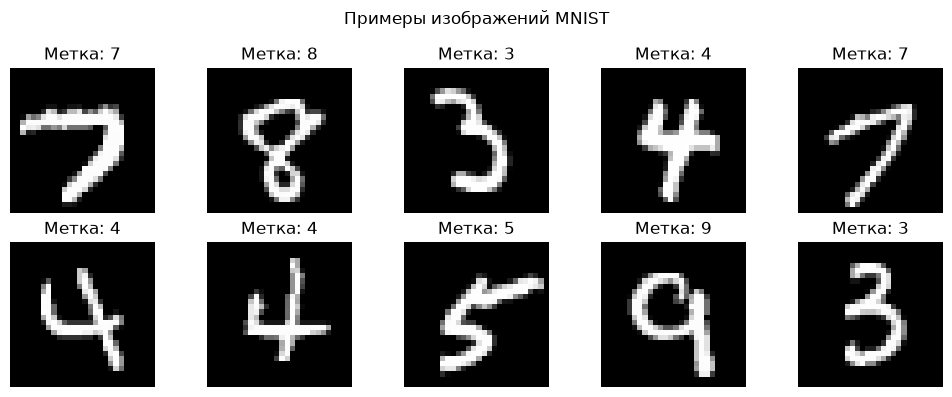

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
indices = np.random.choice(len(X_train), 10, replace=False)
for ax, idx in zip(axes.ravel(), indices):
    ax.imshow(X_train[idx], cmap='gray')
    ax.set_title(f"Метка: {y_train[idx]}")
    ax.axis('off')
plt.suptitle("Примеры изображений MNIST")
plt.tight_layout()
plt.show()

## 2. Предобработка данных

In [5]:
X_train = X_train / 255.0
X_test = X_test / 255.0

X_train = X_train.reshape(-1, 28 * 28)
X_test = X_test.reshape(-1, 28 * 28)

def one_hot(y, num_classes=10):
    out = np.zeros((len(y), num_classes), dtype=np.float32)
    out[np.arange(len(y)), y] = 1.0
    return out

y_train_oh = one_hot(y_train)
y_test_oh = one_hot(y_test)

print("X_train:", X_train.shape, X_train.dtype, "| min/max:", X_train.min(), X_train.max())
print("y_train_oh:", y_train_oh.shape)
print("y_train_oh[0]:", y_train_oh[0])

X_train: (60000, 784) float32 | min/max: 0.0 1.0
y_train_oh: (60000, 10)
y_train_oh[0]: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 3. Прямой проход

In [6]:
def init_params(input_size, hidden_size, output_size):
    W1 = np.random.randn(input_size, hidden_size).astype(np.float32) * np.sqrt(2.0 / input_size)
    b1 = np.zeros(hidden_size, dtype=np.float32)

    W2 = np.random.randn(hidden_size, output_size).astype(np.float32) * np.sqrt(2.0 / (hidden_size + output_size))
    b2 = np.zeros(output_size, dtype=np.float32)
    return W1, b1, W2, b2

def relu(z):
    return np.maximum(0.0, z)

def softmax(z):
    z_shift = z - np.max(z, axis=1, keepdims=True)
    e = np.exp(z_shift)
    return e / np.sum(e, axis=1, keepdims=True)

def forward(X, W1, b1, W2, b2):
    z1 = X @ W1 + b1
    a1 = relu(z1)
    z2 = a1 @ W2 + b2
    a2 = softmax(z2)
    cache = (X, z1, a1)
    return a2, cache

## 4. Обратный проход

In [7]:
def backward(y_pred, y_true, cache, W2):
    X, z1, a1 = cache
    N = X.shape[0]

    dz2 = (y_pred - y_true) / N
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0)

    da1 = dz2 @ W2.T
    dz1 = da1 * (z1 > 0)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0)

    return dW1, db1, dW2, db2

## 5. Метрики

In [8]:
def cross_entropy(y_pred, y_true_oh, eps=1e-12):
    return -np.mean(np.sum(y_true_oh * np.log(y_pred + eps), axis=1))

def accuracy(y_pred, y_true):
    return np.mean(np.argmax(y_pred, axis=1) == y_true)

def evaluate(X, y, y_oh, W1, b1, W2, b2):
    y_pred, _ = forward(X, W1, b1, W2, b2)
    loss = cross_entropy(y_pred, y_oh)
    acc = accuracy(y_pred, y)
    return loss, acc

## 6. Обучение

In [9]:
def train(X, y, y_oh, lr, batch_size, epochs):
    W1, b1, W2, b2 = init_params(input_size=28*28, hidden_size=300, output_size=10)

    n = X.shape[0]
    history = {"loss": [], "train_acc": [], "time": []}

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        perm = np.random.permutation(n)
        X_sh, y_oh_sh = X[perm], y_oh[perm]

        for i in range(0, n, batch_size):
            xb = X_sh[i:i+batch_size]
            yb_oh = y_oh_sh[i:i+batch_size]

            y_pred, cache = forward(xb, W1, b1, W2, b2)
            dW1, db1, dW2, db2 = backward(y_pred, yb_oh, cache, W2)

            W1 -= lr * dW1
            b1 -= lr * db1
            W2 -= lr * dW2
            b2 -= lr * db2

        epoch_time = time.time() - t0
        loss, train_acc = evaluate(X, y, y_oh, W1, b1, W2, b2)

        history["time"].append(epoch_time)
        history["loss"].append(loss)
        history["train_acc"].append(train_acc)

        train_err = 1.0 - train_acc
        print(f"epoch {epoch:2d}/{epochs} | loss={loss:.4f} | "
              f"train_err={train_err*100:5.2f}% | time={epoch_time:.2f}s")

    return W1, b1, W2, b2, history

In [10]:
t_start = time.time()
W1, b1, W2, b2, history = train(
    X_train, y_train, y_train_oh,
    lr=0.1,
    batch_size=64,
    epochs=20,
)
total_time = time.time() - t_start
print(f"\ntotal time: {total_time:.1f}s")

epoch  1/20 | loss=0.2106 | train_err= 5.77% | time=2.42s
epoch  2/20 | loss=0.1488 | train_err= 4.10% | time=2.31s
epoch  3/20 | loss=0.1175 | train_err= 3.35% | time=2.17s
epoch  4/20 | loss=0.0940 | train_err= 2.53% | time=4.50s
epoch  5/20 | loss=0.0774 | train_err= 2.05% | time=2.86s
epoch  6/20 | loss=0.0703 | train_err= 1.90% | time=3.30s
epoch  7/20 | loss=0.0619 | train_err= 1.61% | time=3.85s
epoch  8/20 | loss=0.0510 | train_err= 1.28% | time=2.44s
epoch  9/20 | loss=0.0470 | train_err= 1.23% | time=3.28s
epoch 10/20 | loss=0.0408 | train_err= 1.04% | time=2.80s
epoch 11/20 | loss=0.0350 | train_err= 0.83% | time=3.30s
epoch 12/20 | loss=0.0342 | train_err= 0.81% | time=3.30s
epoch 13/20 | loss=0.0294 | train_err= 0.67% | time=2.21s
epoch 14/20 | loss=0.0270 | train_err= 0.55% | time=2.46s
epoch 15/20 | loss=0.0242 | train_err= 0.48% | time=6.68s
epoch 16/20 | loss=0.0216 | train_err= 0.40% | time=6.76s
epoch 17/20 | loss=0.0200 | train_err= 0.36% | time=5.33s
epoch 18/20 | 

## 7. Результаты

In [11]:
test_loss, test_acc = evaluate(X_test, y_test, y_test_oh, W1, b1, W2, b2)
test_err = 1.0 - test_acc
print(f"Кросс-энтропия на тестовой выборке: {test_loss:.4f}")
print(f"Точность на тестовой выборке: {test_acc*100:.2f}%")
print(f"Ошибка на тестовой выборке: {test_err*100:.2f}%")

Кросс-энтропия на тестовой выборке: 0.0648
Точность на тестовой выборке: 98.02%
Ошибка на тестовой выборке: 1.98%


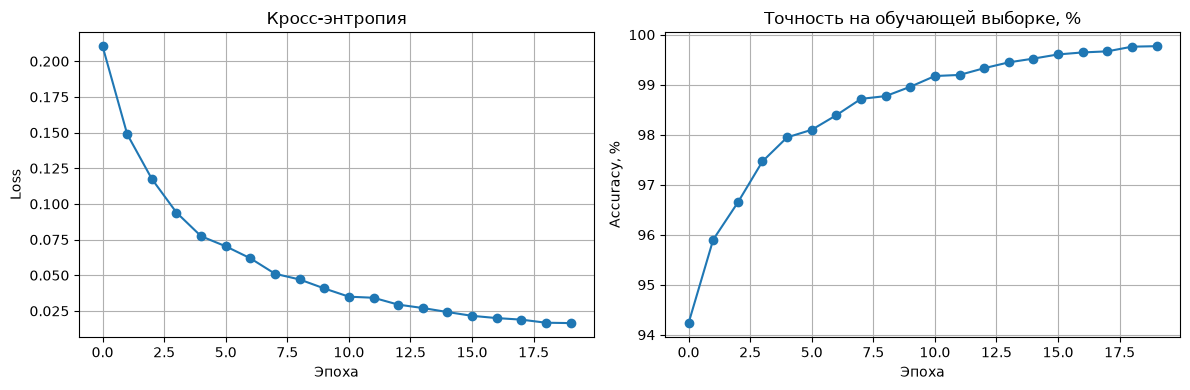

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["loss"], marker='o')
axes[0].set_title("Кросс-энтропия")
axes[0].set_xlabel("Эпоха"); axes[0].set_ylabel("Loss"); axes[0].grid(True)

axes[1].plot(np.array(history["train_acc"])*100, marker='o')
axes[1].set_title("Точность на обучающей выборке, %")
axes[1].set_xlabel("Эпоха"); axes[1].set_ylabel("Accuracy, %"); axes[1].grid(True)

plt.tight_layout()
plt.show()

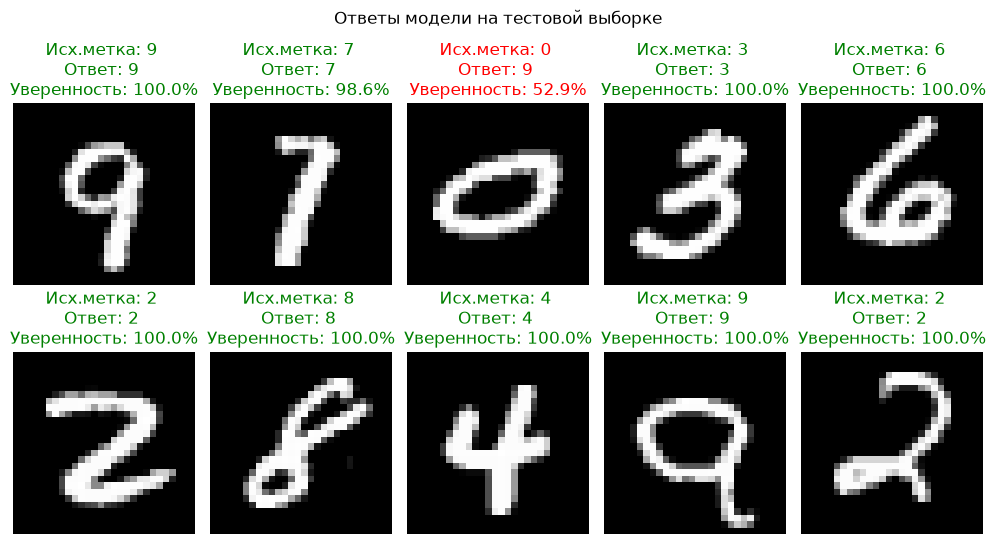

In [13]:
np.random.seed(142)
indices = np.random.choice(len(X_test), 10, replace=False)

x_sel = X_test[indices]
y_sel = y_test[indices]

probs, _ = forward(x_sel, W1, b1, W2, b2)
preds = np.argmax(probs, axis=1)
conf  = np.max(probs, axis=1)

fig, axes = plt.subplots(2, 5, figsize=(10, 5.8))
axes = np.atleast_1d(axes).ravel()

for ax, img, yt, yp, c, pr in zip(axes, x_sel, y_sel, preds, conf, probs):
    ax.imshow(img.reshape(28, 28), cmap='gray')
    correct = (yp == yt)
    color = 'green' if correct else 'red'
    ax.set_title(f"Исх.метка: {yt} \nОтвет: {yp} \nУверенность: {c*100:.1f}%", color=color)
    ax.axis('off')

plt.suptitle("Ответы модели на тестовой выборке")
plt.tight_layout()
plt.show()